# Last-Half-Hour Directional Strategy on CL, 2021–2026 (#30)

This notebook collects the outputs of the strategy backtest in `src/backtest_lh_strategy.py`: the sign-of-ROD timing strategy of Baltussen, Da, Lammers & Martens (2021), Eq. (12), traded on CL with executable fills and explicit costs. It reads only the files the script writes and computes nothing the script does not. Run the script first, from the repository root:

```bash
python -m src.backtest_lh_strategy --config config/lh_strategy.yaml
```

The write-up is `reports/lh_strategy_results.md`. Means are in basis points of notional per trade date with Newey-West standard errors; the Sharpe ratio is annualized with the Lo (2002) standard error; P&L is in USD per contract.

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

root = next(path for path in (Path("."), Path("..")) if (path / "reports/tables").exists())
tables = root / "reports/tables"
figures = root / "reports/figures"

manifest = json.loads((tables / "lh_strategy.manifest.json").read_text())
trades = pd.read_csv(tables / "lh_strategy_trades.csv", parse_dates=["trade_date"])
summary = pd.read_csv(tables / "lh_strategy_summary.csv")
costs = pd.read_csv(tables / "lh_strategy_cost_sensitivity.csv")
by_year = pd.read_csv(tables / "lh_strategy_by_year.csv")
roll_rules = pd.read_csv(tables / "lh_strategy_roll_rules.csv")
robustness = pd.read_csv(tables / "lh_strategy_robustness.csv")
worst = pd.read_csv(tables / "lh_strategy_worst_days.csv")

pd.set_option("display.float_format", lambda value: f"{value:,.2f}")
SIGNALS = {"rod": "Sign of ROD", "onfh": "Sign of ONFH", "onfh_rod_agree": "ONFH and ROD agree", "always_long": "Always Long"}


def interval(frame: pd.DataFrame) -> pd.Series:
	return frame.apply(lambda row: f"[{row['ci_low_bps']:.1f}, {row['ci_high_bps']:.1f}]", axis=1)


def mean_se(frame: pd.DataFrame) -> pd.Series:
	return frame.apply(lambda row: f"{row['mean_bps']:.2f} ({row['se_hac_bps']:.2f})", axis=1)

## 1. Sample, signal and execution

The sample is the paper-filter sample of the minute pipeline (#27). The signal is the sign of ROD = P(13:00 CT) / P(previous 13:30 CT) − 1 from the held contract's reference prices. Fills are the open of the first held-contract bar starting at or after 13:00 and 13:30 CT; the checks below show that this bar traded on every day, so the entry and exit delays are always zero.

In [2]:
checks = manifest["checks"]
execution, cost = manifest["settings"]["execution"], manifest["settings"]["costs"]
pd.Series(
	{
		"trade dates in the sample": checks["sample_days"],
		"first and last date": f"{checks['first_date']} to {checks['last_date']}",
		"traded days (baseline)": checks["baseline_traded_days"],
		"skipped days": checks["baseline_skipped"],
		"entry delay, minutes: days": checks["entry_delay_minutes"],
		"exit delay, minutes: days": checks["exit_delay_minutes"],
		"every entry at or after the decision time": checks["entry_after_decision"],
		"every exit after its entry": checks["exit_after_entry"],
		"entry / exit": f"{execution['fill']} at {execution['entry_time']} / {execution['exit_time']} CT, up to {execution['max_delay_minutes']} minutes late",
		"size": f"{execution['contracts']} contract x USD {execution['multiplier']:,} per 1.00",
		"costs per side": f"USD {cost['commission_per_side_usd']:.2f} commission + {cost['slippage_ticks_per_side']} tick spread/slippage",
		"signal cross-check against #28 features": checks["return_features"],
	},
	name="value",
).to_frame()

,value
trade dates in the sample,1436
first and last date,2021-01-04 to 2026-10-07
traded days (baseline),1435
skipped days,{'no position (signal zero or missing)': 1}
"entry delay, minutes: days",{'0.0': 1436}
"exit delay, minutes: days",{'0.0': 1436}
every entry at or after the decision time,True
every exit after its entry,True
entry / exit,"next_bar_open at 13:00 / 13:30 CT, up to 5 min..."
size,"1 contract x USD 1,000 per 1.00"


In [3]:
trades[trades["traded"]].head(5)[["trade_date", "contract_id", "predictor", "position", "entry_time", "entry_price", "exit_time", "exit_price", "r_lh", "r_gross", "pnl_gross_usd", "cost_usd", "pnl_net_usd"]]

,trade_date,contract_id,predictor,position,entry_time,entry_price,exit_time,exit_price,r_lh,r_gross,pnl_gross_usd,cost_usd,pnl_net_usd
0,2021-01-04,CLG2021,-0.01,-1,2021-01-04 13:00:00-06:00,47.99,2021-01-04 13:30:00-06:00,47.60,-0.01,0.01,390.00,15.00,375.00
1,2021-01-05,CLG2021,0.05,1,2021-01-05 13:00:00-06:00,50.07,2021-01-05 13:30:00-06:00,49.91,-0.00,-0.00,-160.00,15.00,-175.00
2,2021-01-06,CLG2021,0.02,1,2021-01-06 13:00:00-06:00,50.84,2021-01-06 13:30:00-06:00,50.57,-0.01,-0.01,-270.00,15.00,-285.00
3,2021-01-07,CLG2021,0.01,1,2021-01-07 13:00:00-06:00,50.87,2021-01-07 13:30:00-06:00,50.82,-0.00,-0.00,-50.00,15.00,-65.00
4,2021-01-08,CLG2021,0.02,1,2021-01-08 13:00:00-06:00,51.87,2021-01-08 13:30:00-06:00,52.26,0.01,0.01,390.00,15.00,375.00


## 2. Every signal under three accountings

Frictionless is the paper's convention (reference prices, no delay, no costs). Gross uses the next-trade fills without costs; net charges the baseline costs. The paper's Always Long benchmark is included.

In [4]:
table = summary.assign(
	signal=summary["signal"].map(SIGNALS), mean_se=mean_se(summary), interval=interval(summary),
	sharpe_se=summary.apply(lambda row: f"{row['sharpe']:.2f} ({row['sharpe_se']:.2f})", axis=1),
)
table[["signal", "accounting", "traded_days", "long_days", "short_days", "mean_se", "interval", "t_stat_hac", "sharpe_se", "hit_rate", "hit_rate_se", "total_pnl_usd", "max_drawdown_usd", "worst_day_usd", "adverse_days"]].rename(
	columns={"mean_se": "mean bps (SE)", "interval": "95% interval", "t_stat_hac": "t (HAC)", "sharpe_se": "Sharpe (SE)", "hit_rate_se": "hit rate SE"}
)

,signal,accounting,traded_days,long_days,short_days,mean bps (SE),95% interval,t (HAC),Sharpe (SE),hit_rate,hit rate SE,total_pnl_usd,max_drawdown_usd,worst_day_usd,adverse_days
0,Sign of ROD,frictionless,1435,770,665,-1.18 (1.26),"[-3.7, 1.3]",-0.94,-0.40 (0.42),0.48,0.01,NaN,NaN,NaN,NaN
1,Sign of ROD,gross,1435,770,665,-1.15 (1.26),"[-3.6, 1.3]",-0.91,-0.39 (0.42),0.48,0.01,"-9,570.00","23,380.00","-3,670.00",94.00
2,Sign of ROD,net,1435,770,665,-3.15 (1.26),"[-5.6, -0.7]",-2.50,-1.07 (0.42),0.47,0.01,"-31,095.00","39,235.00","-3,685.00",103.00
3,Sign of ONFH,frictionless,1430,786,644,-3.15 (1.21),"[-5.5, -0.8]",-2.60,-1.07 (0.42),0.47,0.01,NaN,NaN,NaN,NaN
4,Sign of ONFH,gross,1430,786,644,-3.09 (1.21),"[-5.5, -0.7]",-2.56,-1.05 (0.42),0.47,0.01,"-38,340.00","41,750.00","-3,670.00",105.00
5,Sign of ONFH,net,1430,786,644,-5.08 (1.21),"[-7.4, -2.7]",-4.21,-1.73 (0.42),0.45,0.01,"-59,790.00","61,850.00","-3,685.00",112.00
6,ONFH and ROD agree,frictionless,1083,602,481,-2.15 (1.11),"[-4.3, 0.0]",-1.95,-0.83 (0.42),0.47,0.02,NaN,NaN,NaN,NaN
7,ONFH and ROD agree,gross,1083,602,481,-2.10 (1.10),"[-4.3, 0.1]",-1.91,-0.81 (0.42),0.47,0.02,"-23,760.00","27,490.00","-3,670.00",75.00
8,ONFH and ROD agree,net,1083,602,481,-3.61 (1.11),"[-5.8, -1.4]",-3.26,-1.39 (0.42),0.46,0.02,"-40,005.00","42,650.00","-3,685.00",81.00
9,Always Long,frictionless,1436,1436,0,-1.42 (1.17),"[-3.7, 0.9]",-1.22,-0.48 (0.42),0.48,0.01,NaN,NaN,NaN,NaN


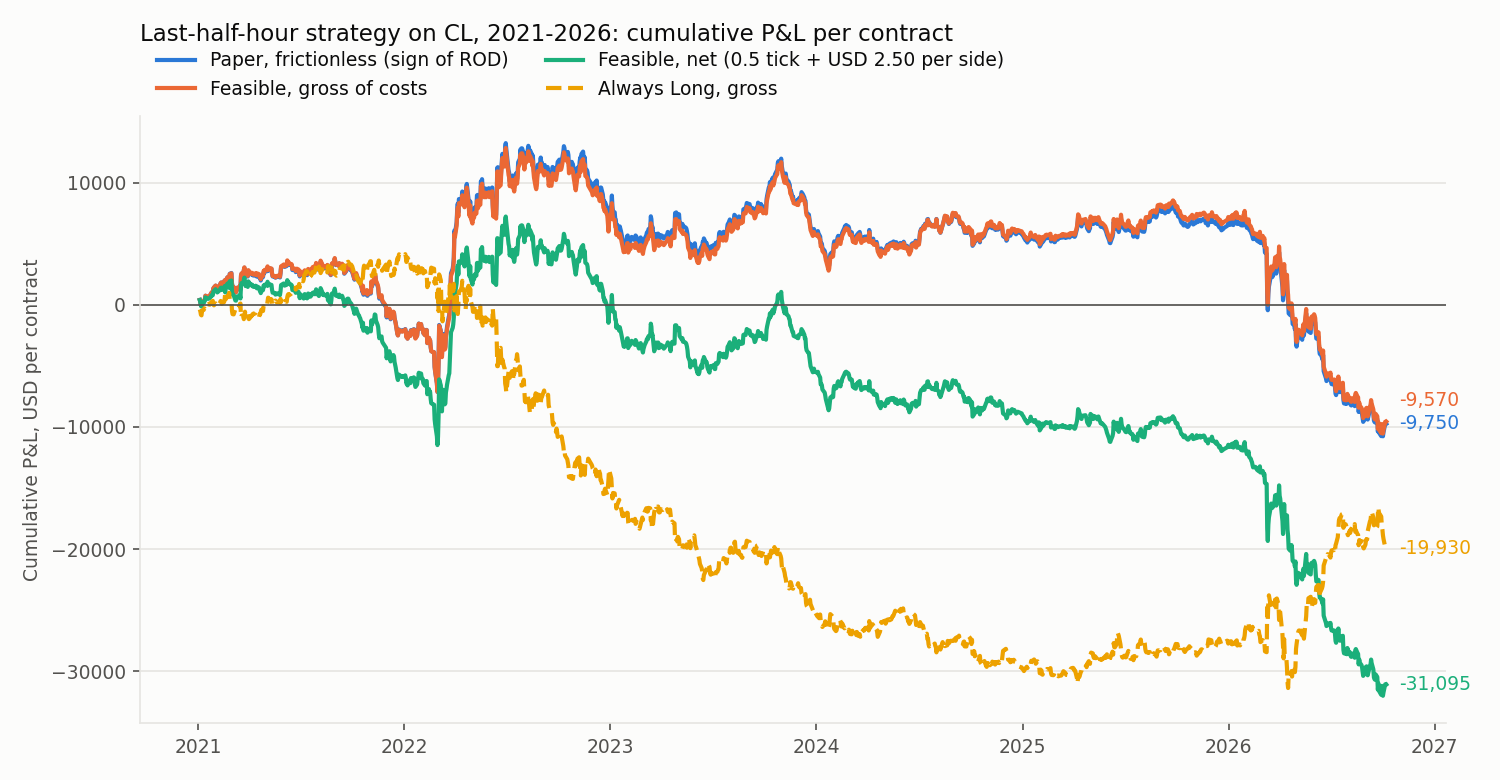

In [5]:
display(Image(filename=figures / "lh_strategy_cumulative.png", width=950))

## 3. Cost sensitivity

The baseline charges USD 2.50 commission and half a tick of spread per side (USD 15 per round trip). There is no quote data, so the spread is a proxy; the grid shows how the net mean moves with it. The breakeven round-trip cost is the mean gross P&L per trade, which is negative, so no cost level makes the strategy profitable.

In [6]:
gross = summary[summary["signal"].eq("rod") & summary["accounting"].eq("gross")].iloc[0]
print(f"Mean gross P&L per round trip: USD {gross['breakeven_cost_per_round_trip_usd']:.2f} ({gross['breakeven_cost_per_round_trip_ticks']:.2f} ticks)")
costs.assign(mean_se=mean_se(costs))[["commission_per_side_usd", "slippage_ticks_per_side", "round_trip_cost_usd", "mean_se", "sharpe", "hit_rate", "total_pnl_usd", "total_cost_usd", "max_drawdown_usd"]].rename(columns={"mean_se": "net mean bps (SE)"})

Mean gross P&L per round trip: USD -6.67 (-0.67 ticks)


,commission_per_side_usd,slippage_ticks_per_side,round_trip_cost_usd,net mean bps (SE),sharpe,hit_rate,total_pnl_usd,total_cost_usd,max_drawdown_usd
0,0.00,0.00,0.00,-1.15 (1.26),-0.39,0.48,"-9,570.00",0.00,"23,380.00"
1,0.00,0.25,5.00,-1.82 (1.26),-0.62,0.48,"-16,745.00","7,175.00","28,665.00"
2,0.00,0.50,10.00,-2.48 (1.26),-0.84,0.47,"-23,920.00","14,350.00","33,950.00"
3,0.00,1.00,20.00,-3.81 (1.26),-1.29,0.46,"-38,270.00","28,700.00","44,520.00"
4,0.00,1.50,30.00,-5.15 (1.26),-1.74,0.45,"-52,620.00","43,050.00","55,090.00"
5,0.00,2.00,40.00,-6.48 (1.26),-2.19,0.42,"-66,970.00","57,400.00","68,800.00"
6,0.00,3.00,60.00,-9.14 (1.27),-3.09,0.40,"-95,670.00","86,100.00","96,780.00"
7,2.50,0.00,5.00,-1.82 (1.26),-0.62,0.48,"-16,745.00","7,175.00","28,665.00"
8,2.50,0.25,10.00,-2.48 (1.26),-0.84,0.47,"-23,920.00","14,350.00","33,950.00"
9,2.50,0.50,15.00,-3.15 (1.26),-1.07,0.47,"-31,095.00","21,525.00","39,235.00"


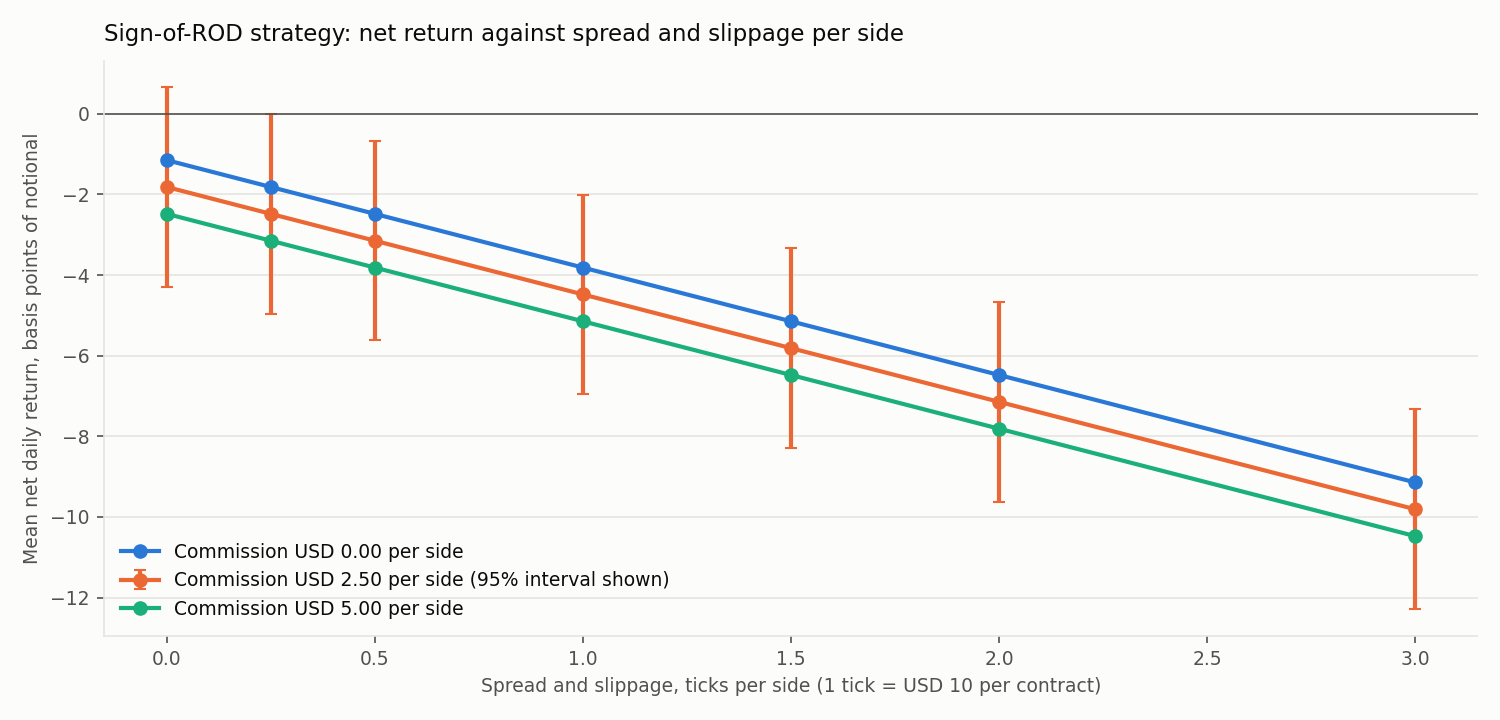

In [7]:
display(Image(filename=figures / "lh_strategy_cost_sensitivity.png", width=950))

## 4. Estimates over time

By calendar year and over a rolling 252-day window. 2026 (to 7 October) is the only year whose interval excludes zero.

In [8]:
by_year.assign(mean_se=mean_se(by_year), interval=interval(by_year))[["year", "accounting", "days", "mean_se", "interval", "sharpe", "hit_rate", "total_pnl_usd", "max_drawdown_usd", "worst_day_usd"]].rename(columns={"mean_se": "mean bps (SE)", "interval": "95% interval"})

,year,accounting,days,mean bps (SE),95% interval,sharpe,hit_rate,total_pnl_usd,max_drawdown_usd,worst_day_usd
0,2021,gross,250,-0.68 (2.38),"[-5.3, 4.0]",-0.28,0.47,"-2,170.00","6,340.00",-860.00
1,2021,net,250,-2.92 (2.36),"[-7.5, 1.7]",-1.21,0.46,"-5,920.00","8,385.00",-875.00
2,2022,gross,249,2.40 (4.39),"[-6.2, 11.0]",0.61,0.51,"8,970.00","6,840.00","-2,040.00"
3,2022,net,249,0.79 (4.41),"[-7.9, 9.4]",0.20,0.49,"5,235.00","8,700.00","-2,055.00"
4,2023,gross,248,-0.94 (2.98),"[-6.8, 4.9]",-0.34,0.48,"-1,030.00","6,040.00","-1,360.00"
5,2023,net,248,-2.88 (2.98),"[-8.7, 3.0]",-1.03,0.48,"-4,750.00","6,580.00","-1,375.00"
6,2024,gross,249,-0.13 (2.15),"[-4.3, 4.1]",-0.06,0.50,140.00,"2,980.00","-1,160.00"
7,2024,net,249,-2.11 (2.15),"[-6.3, 2.1]",-1.05,0.48,"-3,580.00","3,865.00","-1,175.00"
8,2025,gross,248,0.79 (1.81),"[-2.8, 4.3]",0.39,0.50,"1,270.00","2,100.00",-630.00
9,2025,net,248,-1.54 (1.82),"[-5.1, 2.0]",-0.76,0.46,"-2,450.00","3,435.00",-645.00


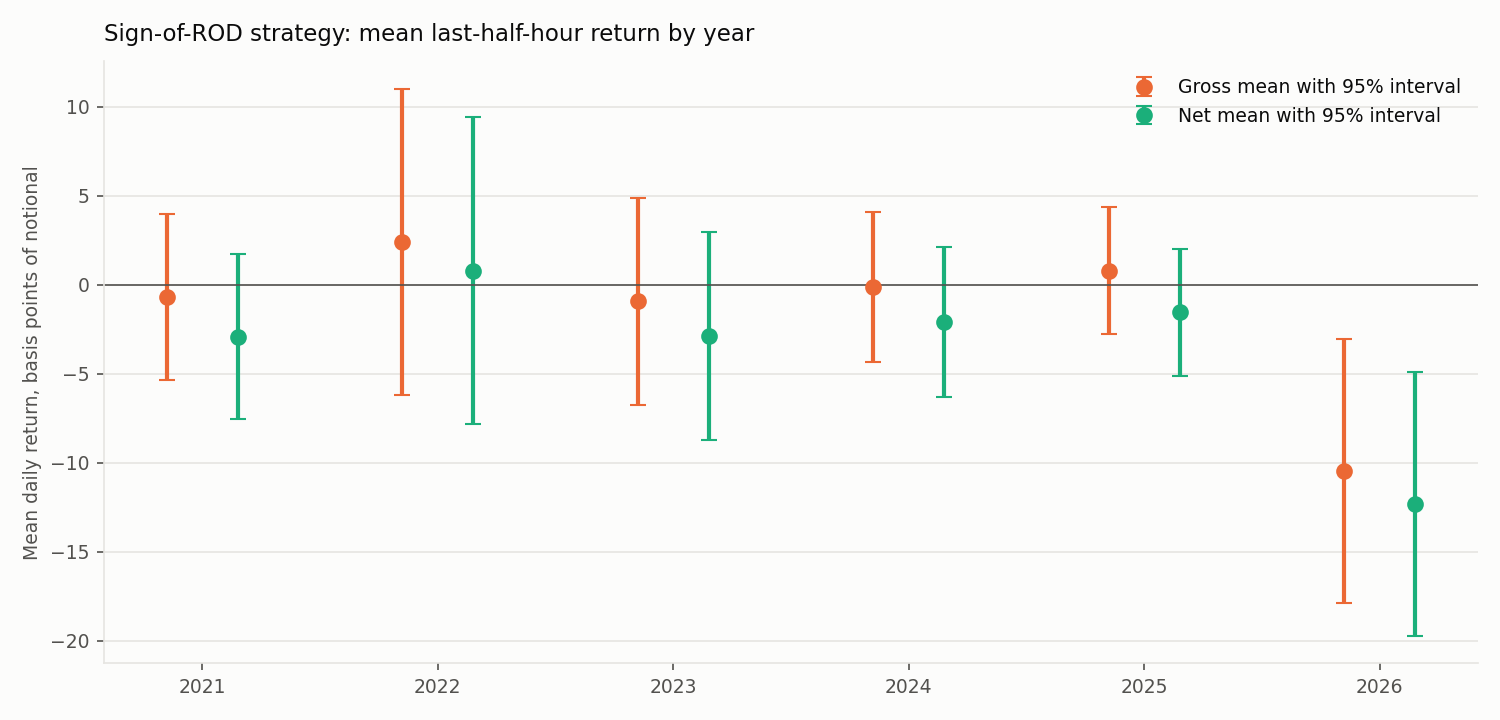

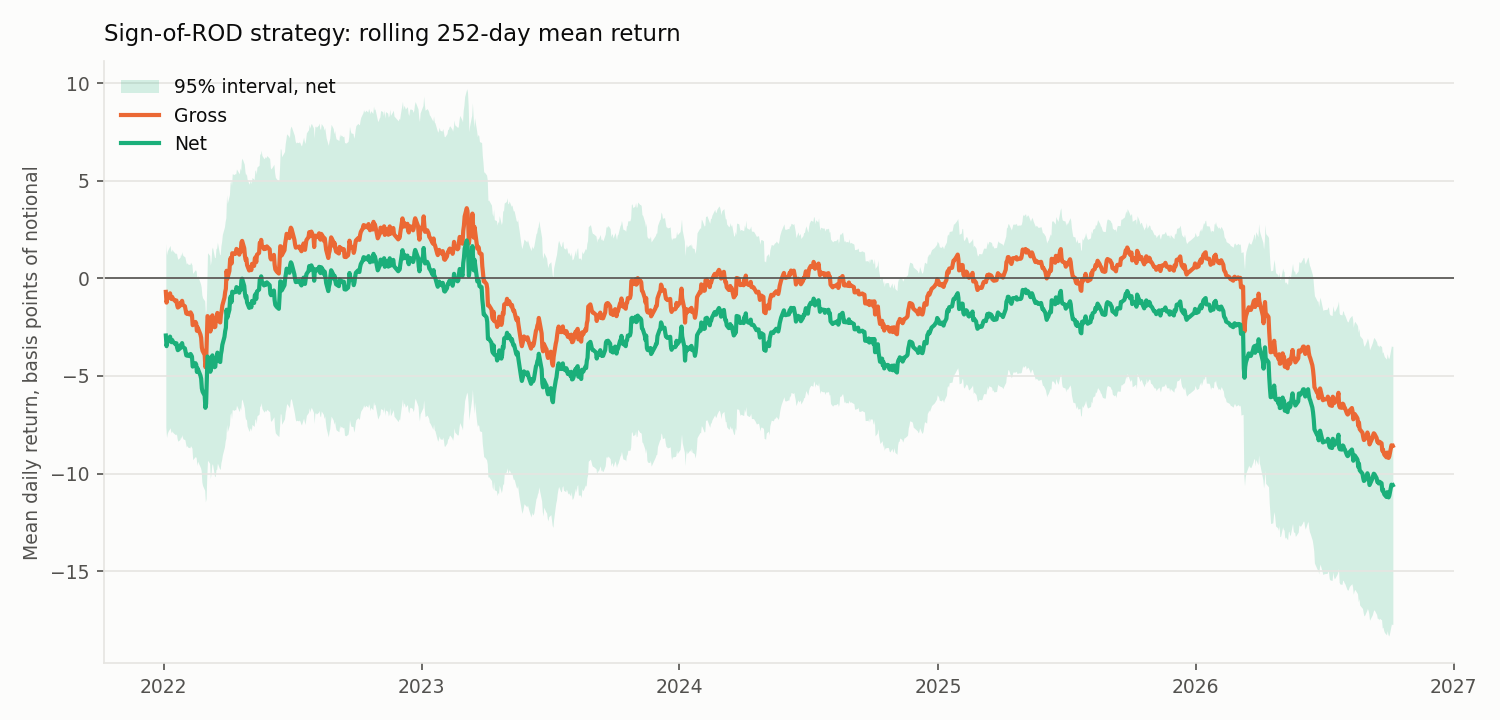

In [9]:
display(Image(filename=figures / "lh_strategy_by_year.png", width=950))
display(Image(filename=figures / "lh_strategy_rolling.png", width=950))

## 5. Roll rules, execution timing and blackouts

The 3-sessions-before-expiry rule holds a different contract on the one or two sessions before each paper roll; its reference prices and fills are rebuilt from the minute bars. The execution variants change the fill convention for the baseline signal; the blackout variants take no position on the listed days.

In [10]:
roll_rules.assign(signal=roll_rules["signal"].map(SIGNALS), mean_se=mean_se(roll_rules))[["roll_rule", "signal", "rolls", "accounting", "traded_days", "mean_se", "sharpe", "hit_rate", "total_pnl_usd"]].rename(columns={"mean_se": "mean bps (SE)"})

,roll_rule,signal,rolls,accounting,traded_days,mean bps (SE),sharpe,hit_rate,total_pnl_usd
0,paper,Sign of ROD,69,frictionless,1435,-1.18 (1.26),-0.40,0.48,NaN
1,paper,Sign of ROD,69,gross,1435,-1.15 (1.26),-0.39,0.48,"-9,570.00"
2,paper,Sign of ROD,69,net,1435,-3.15 (1.26),-1.07,0.47,"-31,095.00"
3,paper,Always Long,69,frictionless,1436,-1.42 (1.17),-0.48,0.48,NaN
4,paper,Always Long,69,gross,1436,-1.33 (1.17),-0.45,0.48,"-19,930.00"
5,paper,Always Long,69,net,1436,-3.33 (1.17),-1.13,0.47,"-41,470.00"
6,pre_expiry_3,Sign of ROD,69,frictionless,1435,-1.22 (1.25),-0.41,0.48,NaN
7,pre_expiry_3,Sign of ROD,69,gross,1435,-1.20 (1.25),-0.41,0.48,"-10,470.00"
8,pre_expiry_3,Sign of ROD,69,net,1435,-3.20 (1.25),-1.09,0.47,"-31,995.00"
9,pre_expiry_3,Always Long,69,frictionless,1436,-1.37 (1.17),-0.46,0.48,NaN


In [11]:
robustness.assign(mean_se=mean_se(robustness), interval=interval(robustness))[["variant", "days_skipped", "accounting", "traded_days", "mean_se", "interval", "sharpe", "hit_rate", "total_pnl_usd", "max_drawdown_usd"]].rename(columns={"mean_se": "mean bps (SE)", "interval": "95% interval"})

,variant,days_skipped,accounting,traded_days,mean bps (SE),95% interval,sharpe,hit_rate,total_pnl_usd,max_drawdown_usd
0,execution:reference_prices,1,frictionless,1435,-1.18 (1.26),"[-3.7, 1.3]",-0.40,0.48,NaN,NaN
1,execution:reference_prices,1,gross,1435,-1.18 (1.26),"[-3.7, 1.3]",-0.40,0.48,"-9,750.00","24,000.00"
2,execution:reference_prices,1,net,1435,-3.18 (1.26),"[-5.7, -0.7]",-1.08,0.46,"-31,275.00","39,855.00"
3,execution:next_bar_open,1,frictionless,1435,-1.18 (1.26),"[-3.7, 1.3]",-0.40,0.48,NaN,NaN
4,execution:next_bar_open,1,gross,1435,-1.15 (1.26),"[-3.6, 1.3]",-0.39,0.48,"-9,570.00","23,380.00"
5,execution:next_bar_open,1,net,1435,-3.15 (1.26),"[-5.6, -0.7]",-1.07,0.47,"-31,095.00","39,235.00"
6,execution:exit_reference_close,1,frictionless,1435,-1.18 (1.26),"[-3.7, 1.3]",-0.40,0.48,NaN,NaN
7,execution:exit_reference_close,1,gross,1435,-1.22 (1.26),"[-3.7, 1.3]",-0.41,0.48,"-10,240.00","23,840.00"
8,execution:exit_reference_close,1,net,1435,-3.22 (1.26),"[-5.7, -0.7]",-1.09,0.46,"-31,765.00","39,695.00"
9,execution:entry_one_minute_late,1,frictionless,1435,-1.18 (1.26),"[-3.7, 1.3]",-0.40,0.48,NaN,NaN


## 6. Adverse days

The ten worst net days. The largest loss is 10 March 2026: a short position after a −15.4% rest-of-day return, which reversed by +4.6% in the last half hour.

In [12]:
worst

,trade_date,contract_id,position,predictor,entry_price,exit_price,r_lh,r_gross,pnl_gross_usd,pnl_net_usd
0,2026-03-10,CLJ2026,-1,-0.15,80.18,83.85,0.05,-0.05,"-3,670.00","-3,685.00"
1,2022-03-08,CLJ2022,1,0.05,125.67,123.63,-0.02,-0.02,"-2,040.00","-2,055.00"
2,2026-04-06,CLK2026,1,0.02,114.07,112.25,-0.02,-0.02,"-1,820.00","-1,835.00"
3,2022-07-05,CLQ2022,-1,-0.10,97.81,99.54,0.02,-0.02,"-1,730.00","-1,745.00"
4,2026-04-30,CLM2026,-1,-0.03,103.67,105.15,0.01,-0.01,"-1,480.00","-1,495.00"
5,2022-06-07,CLN2022,-1,-0.00,118.13,119.56,0.01,-0.01,"-1,430.00","-1,445.00"
6,2026-04-10,CLK2026,1,0.00,97.98,96.55,-0.01,-0.01,"-1,430.00","-1,445.00"
7,2023-03-20,CLK2023,-1,-0.01,66.47,67.83,0.02,-0.02,"-1,360.00","-1,375.00"
8,2026-06-18,CLQ2026,-1,-0.02,74.52,75.84,0.02,-0.02,"-1,320.00","-1,335.00"
9,2022-06-17,CLQ2022,-1,-0.07,106.74,108.05,0.01,-0.01,"-1,310.00","-1,325.00"
